# Fingerprint similarity and the statins
Morgan fingerprints (radius 2, 2,048 bits) and Tanimoto similarity are used throughout. The library has 5,448 drugs, nine of which are statins.

In [2]:
!pip install -q rdkit

import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from rdkit import Chem, DataStructs
from rdkit.Chem import Draw, rdFingerprintGenerator

pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 70)

df = pd.read_csv('drug_library.csv')
df['mol'] = df.smiles.apply(Chem.MolFromSmiles)
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
df['fp'] = df.mol.apply(gen.GetFingerprint)
print(len(df), 'molecules;', df.mol.isna().sum(), 'unreadable SMILES')

5448 molecules; 0 unreadable SMILES


## Part A: The statin family

In [3]:
# type I (fungal) first, then type II (synthetic)
names = ['Lovastatin','Simvastatin','Pravastatin','Mevastatin',
         'Atorvastatin','Fluvastatin','Rosuvastatin','Pitavastatin','Cerivastatin']
statins = df[df.name.isin(names)].set_index('name').loc[names]
print(len(statins), 'statins found')

fps = list(statins.fp)
sim = pd.DataFrame([DataStructs.BulkTanimotoSimilarity(f, fps) for f in fps], index=names, columns=names)
sim.round(2)

9 statins found


,Lovastatin,Simvastatin,Pravastatin,Mevastatin,Atorvastatin,Fluvastatin,Rosuvastatin,Pitavastatin,Cerivastatin
Lovastatin,1.00,0.75,0.85,0.75,0.24,0.20,0.20,0.19,0.20
Simvastatin,0.75,1.00,0.64,0.56,0.21,0.19,0.19,0.19,0.19
Pravastatin,0.85,0.64,1.00,0.74,0.24,0.20,0.20,0.19,0.20
Mevastatin,0.75,0.56,0.74,1.00,0.24,0.20,0.20,0.20,0.20
Atorvastatin,0.24,0.21,0.24,0.24,1.00,0.40,0.31,0.35,0.35
Fluvastatin,0.20,0.19,0.20,0.20,0.40,1.00,0.44,0.54,0.49
Rosuvastatin,0.20,0.19,0.20,0.20,0.31,0.44,1.00,0.45,0.58
Pitavastatin,0.19,0.19,0.19,0.20,0.35,0.54,0.45,1.00,0.51
Cerivastatin,0.20,0.19,0.20,0.20,0.35,0.49,0.58,0.51,1.00


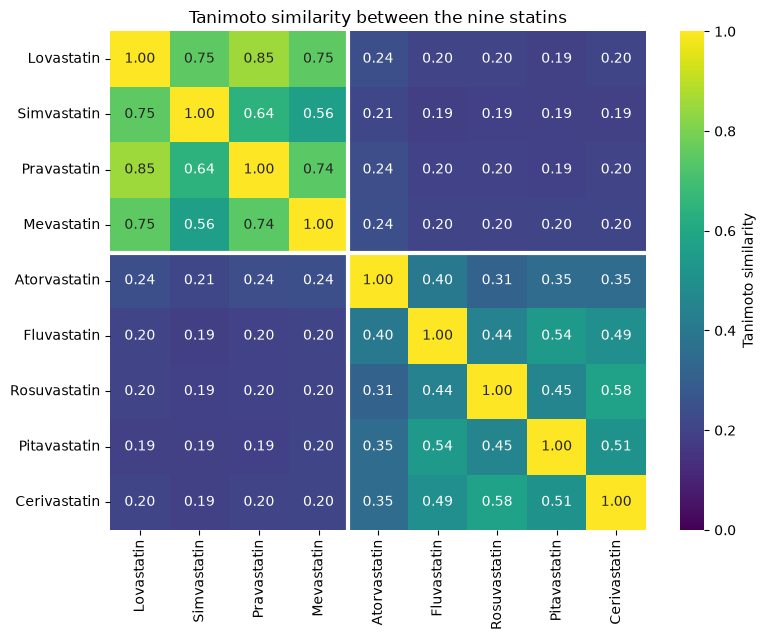

In [4]:
plt.figure(figsize=(8, 6.5))
sns.heatmap(sim, annot=True, fmt='.2f', cmap='viridis', vmin=0, vmax=1, cbar_kws={'label': 'Tanimoto similarity'})
plt.axhline(4, color='white', lw=3); plt.axvline(4, color='white', lw=3)   # type I | type II
plt.title('Tanimoto similarity between the nine statins'); plt.tight_layout(); plt.show()

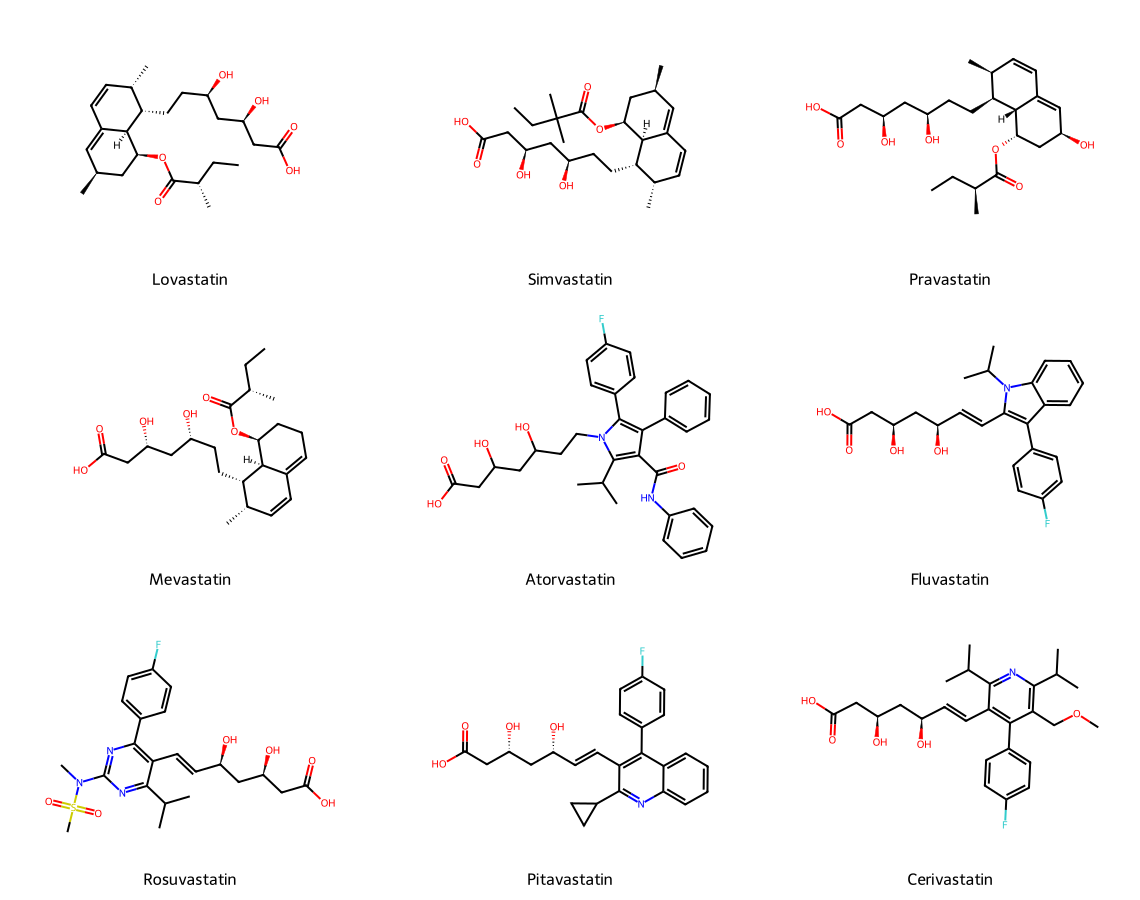

In [5]:
Draw.MolsToGridImage(list(statins.mol), molsPerRow=3, subImgSize=(380, 300), legends=names)

**A.1 Does the matrix separate type I and II?** Yes, it splits into two blocks (white lines).
- **Type I block (top left):** all six pairs are 0.56–0.85. Pravastatin–lovastatin (0.85) is the highest, and simvastatin–lovastatin and mevastatin–lovastatin are 0.75. These are the same fungal decalin (hexahydronaphthalene) scaffold with small changes (an extra methyl or a hydroxyl, or an opened lactone), so they share most of their Morgan environments. They are clearly related.
- **Type II block (bottom right):** the similarities are lower, about 0.45–0.58 for fluvastatin, rosuvastatin, pitavastatin and cerivastatin (e.g. rosuvastatin–cerivastatin 0.58, fluvastatin–pitavastatin 0.54). These four share a flat aromatic core, a fluorophenyl group and the same dihydroxy-heptenoic acid side chain, so they are moderately related. Atorvastatin is the odd one out in this group, with no more than 0.40 to any of them (0.31–0.40), because its pyrrole core has several extra substituents (including the anilide).
- **Between the types:** all type I vs type II pairs are 0.19–0.24, about the level of two random drugs in this library (median about 0.09, 95th percentile about 0.17; computed in B.3). The only feature the two families share is the dihydroxy-acid (HMG-like) side chain, which is a small part of each fingerprint.

So the fingerprints recognise families that share a scaffold, but they do not see that all nine statins bind the same enzyme.

## Part B: Similarity search from lovastatin

In [6]:
query = df[df.name == 'Lovastatin'].iloc[0]
df['sim'] = DataStructs.BulkTanimotoSimilarity(query.fp, list(df.fp))

# exclude the query itself, sort, and number the ranks
rank = df[df.name != 'Lovastatin'].sort_values('sim', ascending=False).reset_index(drop=True)
rank['rank'] = rank.index + 1
print(len(rank), 'molecules ranked')
rank[['rank', 'drugbank_id', 'name', 'sim']].head(15).round(3)

5447 molecules ranked


,rank,drugbank_id,name,sim
0,1,DB00175,Pravastatin,0.855
1,2,DB06693,Mevastatin,0.754
2,3,DB00641,Simvastatin,0.754
3,4,DB03932,LFA703,0.468
4,5,DB08224,"(1S,7S,8S,8AR)-1,2,3,7,8,8A-HEXAHYDRO-7-METHYL-8-[2-[(2R,4R)-TETRA...",0.272
5,6,DB00374,Treprostinil,0.256
6,7,DB00654,Latanoprost,0.244
7,8,DB06846,"7-[3-(4-FLUORO-PHENYL)-1-ISOPROPYL-1H-INDOL-2-YL]-3,5-DIHYDROXY-HE...",0.244
8,9,DB01076,Atorvastatin,0.239
9,10,DB02767,3-Hydroxy-Myristic Acid,0.231


In [7]:
found = rank[rank.name.isin(names)][['rank', 'name', 'sim']].copy()
found['% of library ranked above'] = ((found['rank'] - 1) / len(rank) * 100).round(2)
found.round(3)

,rank,name,sim,% of library ranked above
0,1,Pravastatin,0.855,0.00
1,2,Mevastatin,0.754,0.02
2,3,Simvastatin,0.754,0.04
8,9,Atorvastatin,0.239,0.15
15,16,Cerivastatin,0.204,0.28
19,20,Fluvastatin,0.200,0.35
20,21,Rosuvastatin,0.200,0.37
25,26,Pitavastatin,0.191,0.46


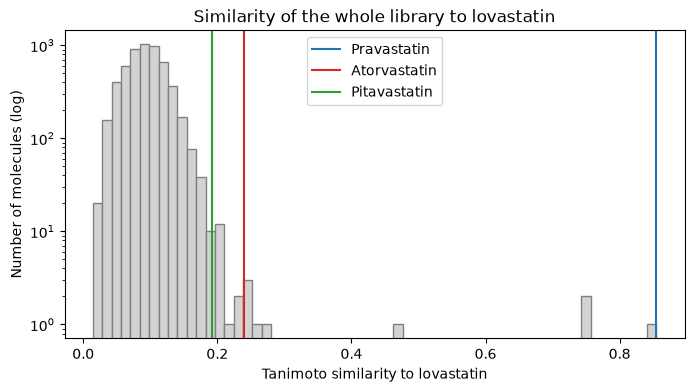

random pairs: median 0.09, 95th pct 0.17, 99th pct 0.26
lovastatin vs library: median 0.09, 99th pct 0.17


In [8]:
# distribution of similarities in the library, for context (B.3)
plt.figure(figsize=(8, 4))
plt.hist(rank.sim, bins=60, color='lightgrey', edgecolor='grey')
for n, c in [('Pravastatin','C0'), ('Atorvastatin','C3'), ('Pitavastatin','C2')]:
    plt.axvline(rank.loc[rank.name == n, 'sim'].iloc[0], color=c, label=n)
plt.yscale('log'); plt.xlabel('Tanimoto similarity to lovastatin'); plt.ylabel('Number of molecules (log)')
plt.legend(); plt.title('Similarity of the whole library to lovastatin'); plt.show()

# similarity between random pairs of drugs
rng = np.random.default_rng(0); fl = list(df.fp)
pairs = rng.integers(0, len(df), (20000, 2)); pairs = pairs[pairs[:, 0] != pairs[:, 1]]
rand = np.array([DataStructs.TanimotoSimilarity(fl[i], fl[j]) for i, j in pairs])
print('random pairs: median %.2f, 95th pct %.2f, 99th pct %.2f' % tuple(np.percentile(rand, [50, 95, 99])))
print('lovastatin vs library: median %.2f, 99th pct %.2f' % tuple(np.percentile(rank.sim, [50, 99])))

**B.2 Ranks of the other statins.** Pravastatin is 1st, simvastatin and mevastatin tie for 2nd/3rd (identical similarity of 0.754), and atorvastatin is 9th. The remaining type II statins fall at ranks 16 (cerivastatin), 20 (rosuvastatin), 22 (fluvastatin) and 26 (pitavastatin). Their similarities (0.19–0.20) are barely above the level of random pairs. Atorvastatin is 9th out of 5,447, so only 8 molecules (0.15% of the library) rank above it.

**B.3 Is lovastatin–atorvastatin similarity (0.24) high?** No. It is far below the type I pairs (0.56–0.85) and it is close to the similarity of two random drugs: the random-pair median is about 0.09 and the 95th percentile about 0.17, so 0.24 sits between the 95th and 99th percentile of random pairs. This is the low "background" tail of the distribution, not the "clearly related" region. It still ranks 9th because the library is large and almost all of it is very dissimilar to lovastatin (median 0.09, 99th percentile 0.17). Once the three true type I analogues and a handful of fragment-like compounds are removed, nothing else has even a moderate score, so a low value of 0.24 is enough to be near the top. A top rank therefore says "few molecules are more similar", not "this molecule is similar". Its 0.24 probably comes mostly from the shared hydroxy-acid side chain, and it is placed above fluvastatin, rosuvastatin and the others by a small margin (0.24 vs 0.20), which is not a meaningful difference.

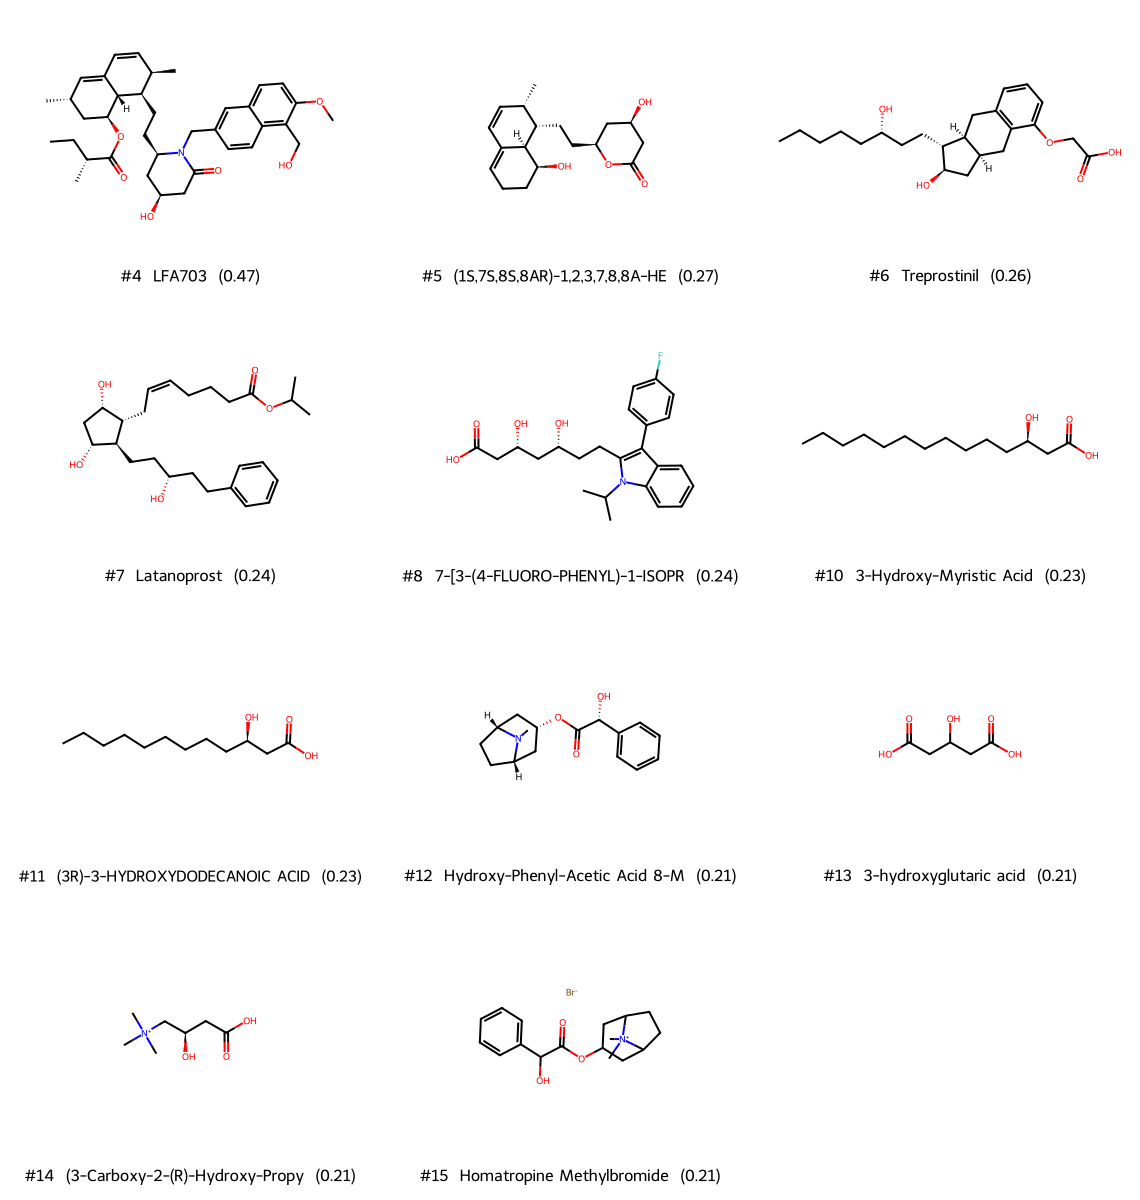

In [9]:
others = rank.head(15)[~rank.head(15).name.isin(names)]
Draw.MolsToGridImage(list(others.mol), molsPerRow=3, subImgSize=(380, 300),
                     legends=[f"#{r}  {n[:30]}  ({s:.2f})" for r, n, s in zip(others['rank'], others.name, others.sim)])

**B.4 The non-statins in the top 15.** They share with lovastatin chiefly the pieces that fingerprints count most easily: hydroxyl groups, a carboxylic acid or lactone/ester, an aliphatic ring and a flexible chain.
- **LFA703 (#4, 0.47)**: this is the lovastatin skeleton with a large group added at the lactone. It is a genuine analogue, but it was developed as an LFA-1 (immune cell adhesion) inhibitor, not for cholesterol.
- **#5 (hexahydronaphthalene with a hydroxy-lactone, 0.27)** and **#8 (fluorophenyl-isopropyl-indole dihydroxy-heptanoic acid, 0.24)**: these are experimental compounds that resemble lovastatin's decalin-lactone and fluvastatin respectively. Both have the statin pharmacophore, so they are plausible HMG-CoA reductase inhibitors (they look like crystallography ligands or statin analogues).
- **Treprostinil and latanoprost (#6, #7), the hydroxy fatty acids (#10, #11), 3-hydroxyglutaric acid (#13)** and the rest (#12, #14, #15): these have a hydroxy-acid chain and/or a ring but no statin scaffold. Prostaglandin analogues act on prostanoid receptors, the others are metabolites or tropane-like anticholinergics.

**Recommendation:** I would test #5 and #8 (and LFA703 for completeness) as likely enzyme inhibitors, though they are not new, patentable drugs and LFA703 was optimised for a different target. I would not test the rest of the list: I would expect no HMG-CoA reductase inhibition, because their similarity (0.20–0.26) comes from generic fragments (hydroxyl, acid, chain), not from the combination of groups needed to fit the enzyme's active site.

## Part C: What similarity cannot tell you

Lovastatin      0.11
Simvastatin     0.12
Pravastatin     0.11
Mevastatin      0.11
Atorvastatin    0.18
Fluvastatin     0.18
Rosuvastatin    0.16
Pitavastatin    0.17
Cerivastatin    0.18

Ezetimibe: similarity to lovastatin 0.11, rank 1384 of 5447 (top 25% of the library)


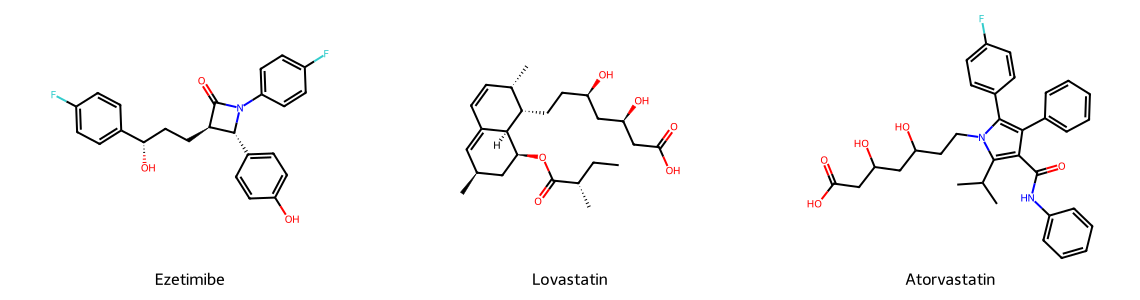

In [10]:
ez = df[df.name == 'Ezetimibe'].iloc[0]
ez_sim = pd.Series(DataStructs.BulkTanimotoSimilarity(ez.fp, fps), index=names, name='Ezetimibe')
print(ez_sim.round(2).to_string())
r = rank[rank.name == 'Ezetimibe'].iloc[0]
print(f"\nEzetimibe: similarity to lovastatin {r.sim:.2f}, rank {int(r['rank'])} of {len(rank)}"
      f" (top {100*r['rank']/len(rank):.0f}% of the library)")
Draw.MolsToGridImage([ez.mol, query.mol, df[df.name=='Atorvastatin'].iloc[0].mol], molsPerRow=3,
                     subImgSize=(380, 300), legends=['Ezetimibe', 'Lovastatin', 'Atorvastatin'])

**C.1 Ezetimibe.** Its similarity to every statin is low (0.11–0.12 to the four type I statins and 0.16–0.18 to the type II ones, highest at 0.18 for atorvastatin, fluvastatin and cerivastatin). Against lovastatin it is 0.11 and it ranks 1,414th out of 5,447, in the top 26% of the library only because almost everything is dissimilar; it is indistinguishable from typical unrelated drugs. This is what we would expect, because ezetimibe is a β-lactam (azetidinone) with two fluorophenyl groups and a hydroxyl; it has no decalin and no HMG-like acid chain, and it acts on a different target (the NPC1L1 cholesterol transporter) by a different mechanism. Fingerprints compare structure, and the structures are different, so the similarity is low even though the therapeutic use is the same.

**C.2 Would the search have helped the company?** Starting from lovastatin alone, the search would have found the close fungal analogues (pravastatin, simvastatin, mevastatin; 0.75–0.85) and they are real statins, but they are also the compounds that would be *hardest to patent*, because they are too similar to lovastatin and are already known. Atorvastatin did appear in the top 10, but only at 0.24, indistinguishable from the fragment-like noise around it. A scientist would have had to work through eight other compounds above it and would have no reason to expect it to be active, so it would be found only by a very generous testing budget, or by luck. The other type II statins sat at ranks 16–26 with similarities that are no better than random pairs, so the "few dozen compounds to test first" would have included them only by chance. Ezetimibe, at rank 1,414, would have been missed completely. In summary, fingerprint similarity finds molecules that share substructures and so works well for finding close analogues (the same scaffold, small modifications), which is useful for optimising a series or for finding backups, but it has no knowledge of the target, binding mode or pharmacophore. It therefore cannot find a structurally new compound that works in the same way (atorvastatin), nor a different compound with the same effect by a different mechanism (ezetimibe), and it can even rank unrelated drugs above true actives when they share generic features. Finding new chemotypes needs methods that describe function (3D pharmacophores, docking, or information from the target), not only the 2D structure.